Loading the Data

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns

In [3]:
df = pd.read_csv("emotion_dataset_raw.csv")

In [5]:
df.head()

,Emotion,Text
0,neutral,Why ?
1,joy,Sage Act upgrade on my to do list for tommorow.
2,sadness,ON THE WAY TO MY HOMEGIRL BABY FUNERAL!!! MAN ...
3,joy,Such an eye ! The true hazel eye-and so brill...
4,joy,@Iluvmiasantos ugh babe.. hugggzzz for u .! b...


<Axes: xlabel='Emotion', ylabel='count'>

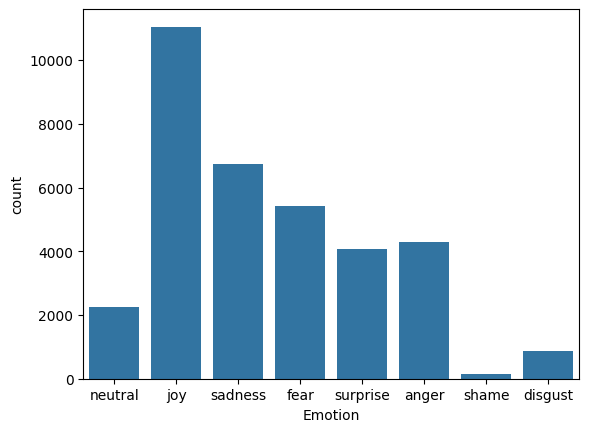

In [6]:
sns.countplot(x="Emotion",data=df)

Pre-Processing the Data


In [12]:
%pip install nltk
%pip install swifter

Note: you may need to restart the kernel to use updated packages.
     ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
     ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
     ------

In [22]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import re
import swifter
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


True

In [64]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    if not isinstance(text,str):
        return ""
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [lemmatizer.lemmatize(word) for word in tokens] 
    return " ".join(tokens)


In [65]:
df['cleaned_text'] = df['Text'].swifter.apply(clean_text)

Pandas Apply: 100%|██████████| 34792/34792 [00:04<00:00, 8396.12it/s]


In [66]:
df

,Emotion,Text,cleaned_text
0,neutral,Why ?,
1,joy,Sage Act upgrade on my to do list for tommorow.,sage act upgrade list tommorow
2,sadness,ON THE WAY TO MY HOMEGIRL BABY FUNERAL!!! MAN ...,way homegirl baby funeral man hate funeral rea...
3,joy,Such an eye ! The true hazel eye-and so brill...,eye true hazel eyeand brilliant regular featur...
4,joy,@Iluvmiasantos ugh babe.. hugggzzz for u .! b...,iluvmiasantos ugh babe huggzz u babe naamazed ...
...,...,...,...
34787,surprise,@MichelGW have you gift! Hope you like it! It'...,michelgw gift hope like hand made wear itll ke...
34788,joy,The world didnt give it to me..so the world MO...,world didnt give meso world definitely cnt tak...
34789,anger,A man robbed me today .,man robbed today
34790,fear,"Youu call it JEALOUSY, I call it of #Losing YO...",youu call jealousy call losing


splitting data

In [67]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, classification_report


In [68]:
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
x = vectorizer.fit_transform(df['cleaned_text'])
y = df['Emotion']
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [69]:
lr = LogisticRegression(max_iter=200)
lr.fit(x_train, y_train)

LogisticRegression(max_iter=200)

In [70]:
nb = MultinomialNB()
nb.fit(x_train, y_train)

MultinomialNB()

In [71]:
svm = LinearSVC()
svm.fit(x_train, y_train)

LinearSVC()

In [72]:
sgd = SGDClassifier(loss='log_loss', max_iter=1000, random_state=42)
sgd.fit(x_train, y_train)

SGDClassifier(loss='log_loss', random_state=42)

In [73]:
models = {
    "LogisticRegression": lr,
    "Naive Bayes": nb,
    "SVM": svm,
    "SGD": sgd
}

for name, model in models.items():
    y_pred = model.predict(x_test)
    print(f"=== {name} ===")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))
    print()

=== LogisticRegression ===
Accuracy: 0.6130191119413709
              precision    recall  f1-score   support

       anger       0.64      0.55      0.59       836
     disgust       0.77      0.10      0.18       202
        fear       0.74      0.63      0.68      1104
         joy       0.58      0.82      0.68      2214
     neutral       0.68      0.35      0.46       481
     sadness       0.58      0.60      0.59      1327
       shame       0.75      0.39      0.51        23
    surprise       0.60      0.40      0.48       772

    accuracy                           0.61      6959
   macro avg       0.67      0.48      0.52      6959
weighted avg       0.63      0.61      0.60      6959


=== Naive Bayes ===
Accuracy: 0.5710590602098002
              precision    recall  f1-score   support

       anger       0.68      0.44      0.54       836
     disgust       0.00      0.00      0.00       202
        fear       0.81      0.53      0.64      1104
         joy       0.50   

c:\Users\user\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\user\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\user\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Saving Model based on Best Results


In [74]:
import joblib
joblib.dump(svm,"emotion.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

['tfidf_vectorizer.pkl']